# 🚀 Análisis Exploratorio — La industria espacial en cifras

Proyecto **Órbita**: datos de todos los lanzamientos orbitales desde 1957
hasta hoy, obtenidos de la API pública **Launch Library 2** (The Space Devs).

Este cuaderno responde a preguntas como:

- ¿Cuántos lanzamientos ha habido y cómo ha evolucionado la actividad?
- ¿Qué agencias dominan el sector y con qué fiabilidad?
- ¿Qué cohetes son los más usados y los más fiables?
- ¿Hacia qué órbitas se lanza y desde dónde?
- ¿Cuántas personas han volado al espacio?
- ¿Qué lanzamientos nos esperan en los próximos meses?

Cada sección termina con una **conclusión escrita** en texto.


## 0. Preparación

Cargamos las librerías y un helper para leer la base de datos SQLite.


In [1]:
import sqlite3
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo y opciones de visualización
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 95
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

DB = "../data/espacio.db"


def query(sql, params=None):
    """Ejecuta una consulta y devuelve un DataFrame."""
    conn = sqlite3.connect(DB)
    try:
        return pd.read_sql_query(sql, conn, params=params)
    finally:
        conn.close()


In [2]:
# Tablas de la base de datos
for tabla in ["launches", "agencies", "astronauts", "locations", "pads"]:
    n = query(f"SELECT COUNT(*) AS n FROM {tabla}").iloc[0, 0]
    print(f"{tabla:12s} -> {n:>7,} filas")


launches     ->   7,943 filas
agencies     ->     350 filas
astronauts   ->     858 filas
locations    ->      53 filas
pads         ->     238 filas


## 1. Primer vistazo a los lanzamientos

Cargamos todos los lanzamientos y preparamos la columna de fecha.


In [3]:
launch = query("SELECT * FROM launches")
print(f"{len(launch):,} lanzamientos registrados "
      f"(desde {launch['net'].min()} hasta {launch['net'].max()})")

# Fechas: eliminamos la 'Z' final y convertimos
launch["net_dt"] = pd.to_datetime(launch["net"], errors="coerce")
launch["anio"] = launch["net_dt"].dt.year
print(f"Lanzamientos con fecha válida: {launch['net_dt'].notna().sum():,}")
launch[["name", "net", "status_name", "rocket_name", "agency_name",
        "orbit"]].head(10)


7,943 lanzamientos registrados (desde 1957-10-04T19:28:34Z hasta 2039-12-31T00:00:00Z)
Lanzamientos con fecha válida: 7,943


,name,net,status_name,rocket_name,agency_name,orbit
0,Sputnik 8K74PS | Sputnik 1,1957-10-04T19:28:34Z,Success,Sputnik 8K74PS,Soviet Space Program,Low Earth Orbit
1,Sputnik 8K74PS | Sputnik 2,1957-11-03T02:30:00Z,Success,Sputnik 8K74PS,Soviet Space Program,Low Earth Orbit
2,Vanguard | Vanguard,1957-12-06T16:44:35Z,Failure,Vanguard,US Navy,Low Earth Orbit
3,Juno-I | Explorer 1,1958-02-01T03:47:56Z,Success,Juno-I,Army Ballistic Missile Agency,Low Earth Orbit
4,Vanguard | Vanguard,1958-02-05T07:33:00Z,Failure,Vanguard,US Navy,Low Earth Orbit
5,Juno-I | Explorer 2,1958-03-05T18:27:57Z,Failure,Juno-I,Army Ballistic Missile Agency,Low Earth Orbit
6,Vanguard | Vanguard,1958-03-17T12:15:41Z,Success,Vanguard,US Navy,Low Earth Orbit
7,Juno-I | Explorer 3,1958-03-26T17:38:01Z,Success,Juno-I,Army Ballistic Missile Agency,Elliptical Orbit
8,Sputnik 8A91 | D-1 1,1958-04-27T07:00:35Z,Failure,Sputnik 8A91,Soviet Space Program,Low Earth Orbit
9,Vanguard | Vanguard,1958-04-29T02:53:00Z,Failure,Vanguard,US Navy,Low Earth Orbit


In [4]:
# Estado y datos incompletos
print("Valores nulos por columna clave:")
launch[["name", "net", "status_name", "rocket_name",
        "agency_name", "orbit"]].isna().sum()


Valores nulos por columna clave:


name             0
net              0
status_name      0
rocket_name      0
agency_name      0
orbit          540
dtype: int64

## 2. Evolución histórica de los lanzamientos

De 3 lanzamientos en 1957 a más de 200 al año hoy. Veamos la serie completa.


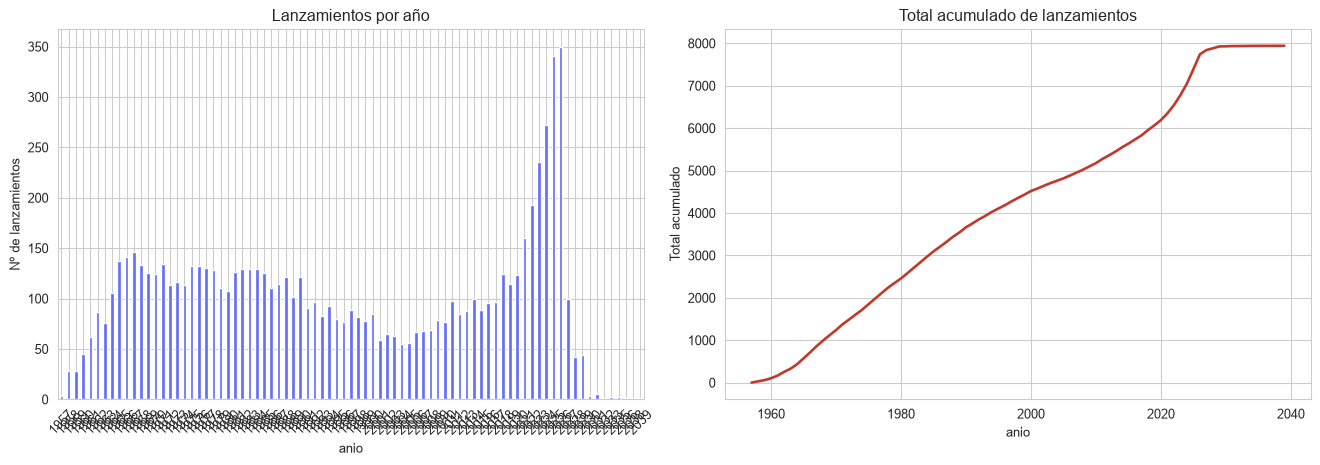

In [5]:
por_anio = launch.groupby("anio").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
por_anio.plot(kind="bar", ax=axes[0], color="#636efa")
axes[0].set_title("Lanzamientos por año")
axes[0].set_ylabel("Nº de lanzamientos")
axes[0].tick_params(axis="x", rotation=45)

por_anio.cumsum().plot(ax=axes[1], color="#c0392b", linewidth=2)
axes[1].set_title("Total acumulado de lanzamientos")
axes[1].set_ylabel("Total acumulado")
plt.tight_layout()
plt.show()


In [6]:
# Crecimiento por década
decadas = (por_anio.index // 10 * 10).to_series(index=por_anio.index)
print(por_anio.groupby(decadas).sum().rename("lanzamientos"))


anio
1950      59
1960    1058
1970    1232
1980    1193
1990     891
2000     666
2010     968
2020    1860
2030      16
Name: lanzamientos, dtype: int64


**Conclusión 2:** la actividad espacial pasó de ser un duelo entre dos
superpotencias (picos en las décadas de 1960-80) a una industria global en
plena expansión. Desde 2010 el crecimiento es espectacular: se lanza más en
un año (superando los 250 en 2023) que en toda la década de 1970. La bajada
de 2014-2016 refleja la crisis del mercado de lanzamiento comercial previa a
la consolidación de los lanzadores reutilizables.


## 3. Estados y tasa de éxito

¿Cuántos lanzamientos fracasan? Analizamos los estados y la tasa de éxito.


status_name
Success            7022
Failure             522
TBD                 354
Partial Failure      34
Go                   11
Name: count, dtype: int64


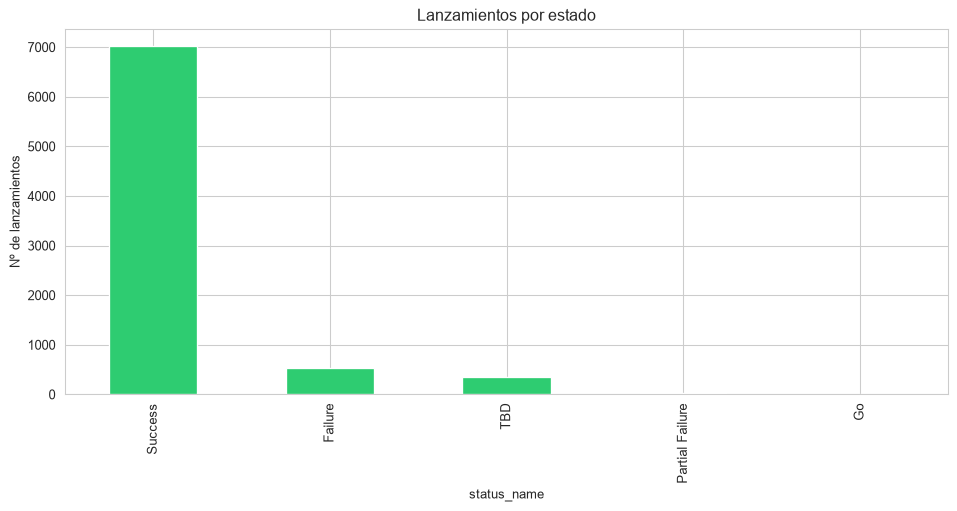

In [7]:
estados = launch["status_name"].value_counts()
print(estados)
estados.plot(kind="bar", color="#2ecc71")
plt.title("Lanzamientos por estado")
plt.ylabel("Nº de lanzamientos")
plt.show()


Tasa de éxito global: 92.7% (7,578 lanzamientos decididos)


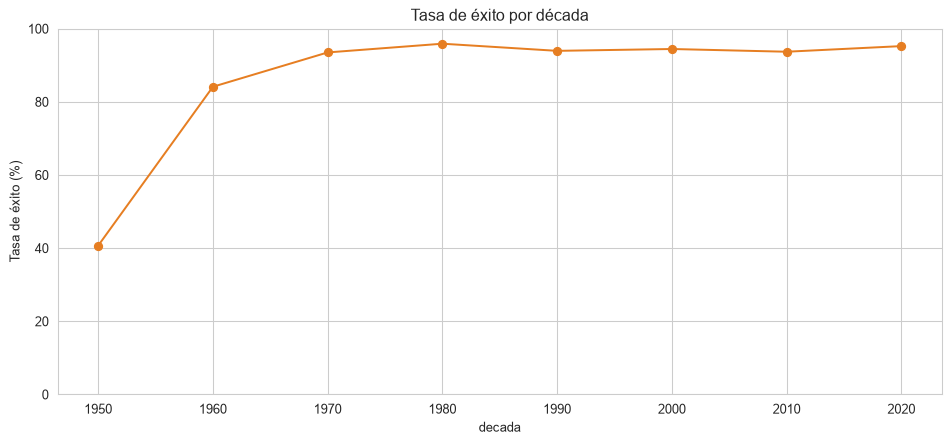

         total  exitos     tasa_%
decada                           
1950      59.0    24.0  40.677966
1960    1058.0   890.0  84.120983
1970    1232.0  1152.0  93.506494
1980    1193.0  1144.0  95.892707
1990     891.0   837.0  93.939394
2000     666.0   629.0  94.444444
2010     968.0   907.0  93.698347
2020    1511.0  1439.0  95.234944


In [8]:
# Tasa de éxito global (excluyendo los sin decidir: TBD/TBC/Go)
decididos = launch[launch["status_name"].isin(
    ["Success", "Failure", "Partial Failure", "Failed Launch"]
)]
tasa_global = (decididos["status_name"] == "Success").mean() * 100
print(f"Tasa de éxito global: {tasa_global:.1f}% "
      f"({len(decididos):,} lanzamientos decididos)")

# Tasa de éxito por década
decididos["decada"] = (decididos["anio"] // 10 * 10)
por_decada = decididos.groupby("decada").apply(
    lambda d: pd.Series({
        "total": len(d),
        "exitos": (d["status_name"] == "Success").sum(),
        "tasa_%": (d["status_name"] == "Success").mean() * 100,
    }),
    include_groups=False,
)
por_decada.plot(y="tasa_%", kind="line", marker="o", color="#e67e22", legend=False)
plt.title("Tasa de éxito por década")
plt.ylabel("Tasa de éxito (%)")
plt.ylim(0, 100)
plt.show()
print(por_decada)


**Conclusión 3:** la tasa de éxito global supera el 90 %. Ha mejorado de
forma casi constante: del ~85 % en la era del Sputnik a más del 95 % en la
última década. Los cohetes modernos y la industria privada (reutilización,
fabricación en cadena) han hecho que el espacio sea, hoy, un negocio fiable.


## 4. ¿Quién domina el espacio? Las agencias

Las agencias de lanzamiento ordenadas por actividad y fiabilidad.


                                                    lanzamientos  exitos     tasa_%
agency_name                                                                        
Soviet Space Program                                        2453    2285  93.151243
United States Air Force                                     1078     972  90.166976
SpaceX                                                       839     696  82.955900
China Aerospace Science and Technology Corporation           616     592  96.103896
Arianespace                                                  355     312  87.887324
Russian Federal Space Agency (ROSCOSMOS)                     349     332  95.128940
United Launch Alliance                                       211     175  82.938389
Khrunichev State Research and Production Space ...           193     178  92.227979
Russian Space Forces                                         157     148  94.267516
National Aeronautics and Space Administration                141     116  82

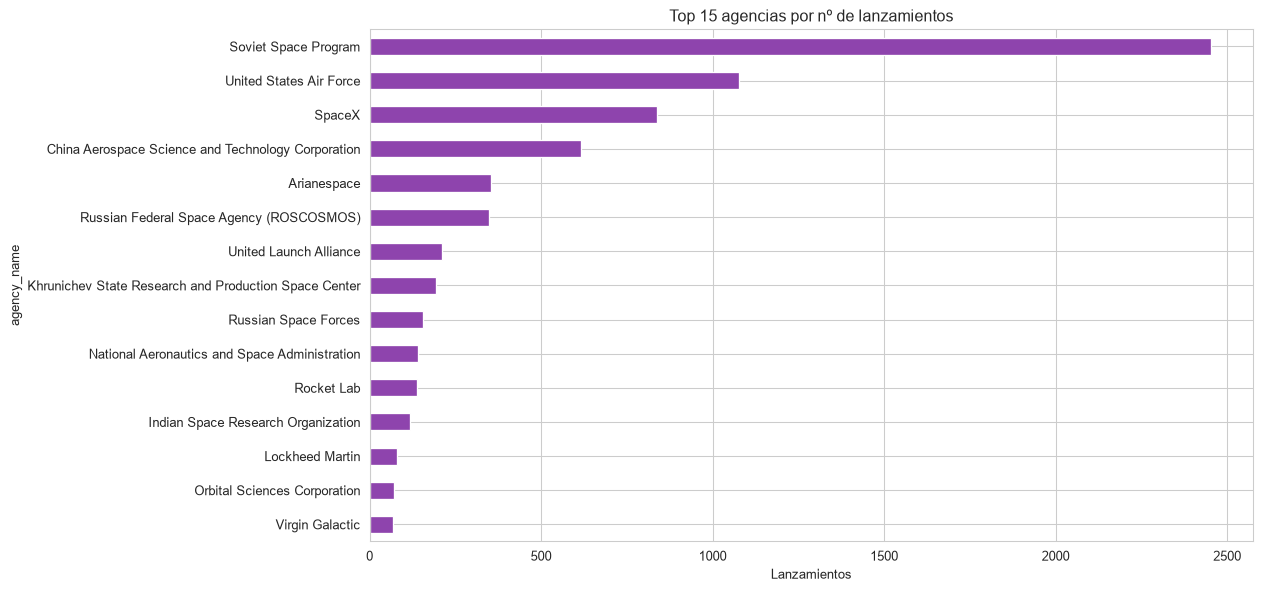

In [9]:
top_agencias = launch.groupby("agency_name").agg(
    lanzamientos=("id", "count"),
    exitos=("status_name", lambda s: (s == "Success").sum()),
).sort_values("lanzamientos", ascending=False).head(15)
top_agencias["tasa_%"] = top_agencias["exitos"] / top_agencias["lanzamientos"] * 100
print(top_agencias)

top_agencias["lanzamientos"].plot(kind="barh", color="#8e44ad", figsize=(12, 7))
plt.gca().invert_yaxis()
plt.title("Top 15 agencias por nº de lanzamientos")
plt.xlabel("Lanzamientos")
plt.show()


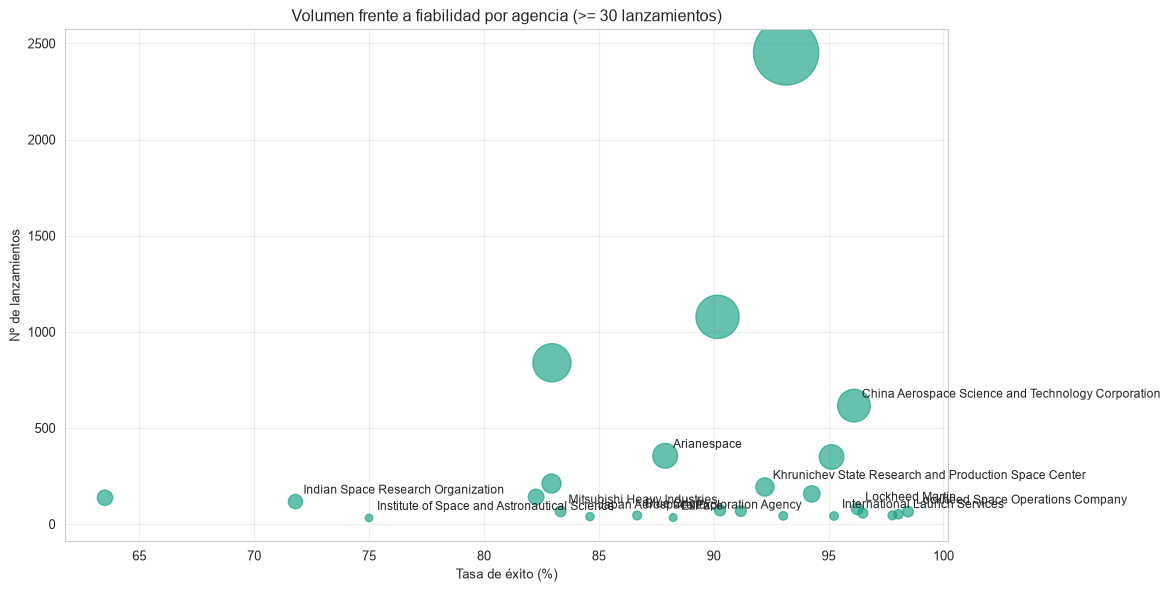

In [10]:
# Fiabilidad frente a volumen (solo agencias con >= 30 lanzamientos)
activas = launch.groupby("agency_name").agg(
    lanzamientos=("id", "count"),
    exitos=("status_name", lambda s: (s == "Success").sum()),
).reset_index()
activas = activas[activas["lanzamientos"] >= 30].copy()
activas["tasa_%"] = activas["exitos"] / activas["lanzamientos"] * 100

plt.figure(figsize=(12, 7))
sc = plt.scatter(
    activas["tasa_%"], activas["lanzamientos"],
    s=activas["lanzamientos"], alpha=0.65, c="#16a085",
)
for _, f in activas.head(12).iterrows():
    plt.annotate(f["agency_name"], (f["tasa_%"], f["lanzamientos"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=9)
plt.xlabel("Tasa de éxito (%)")
plt.ylabel("Nº de lanzamientos")
plt.title("Volumen frente a fiabilidad por agencia (>= 30 lanzamientos)")
plt.grid(True, alpha=0.3)
plt.show()


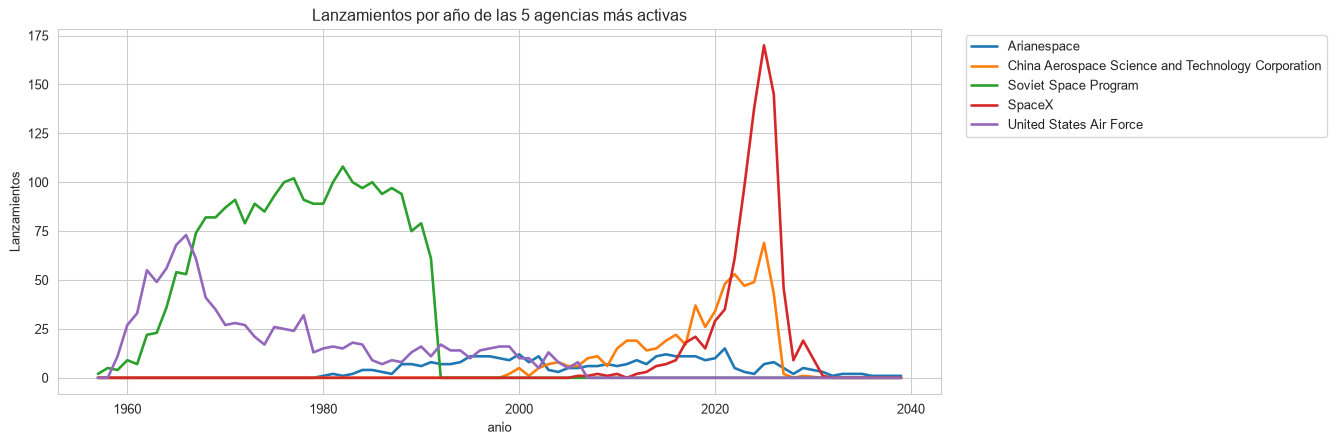

In [11]:
# Carrera de las 5 agencias más activas: lanzamientos por año
top5 = launch[launch["agency_name"].isin(top_agencias.index[:5])]
tabla = top5.pivot_table(index="anio", columns="agency_name",
                         values="id", aggfunc="count").fillna(0)
tabla.plot(kind="line", linewidth=2)
plt.title("Lanzamientos por año de las 5 agencias más activas")
plt.ylabel("Lanzamientos")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


**Conclusión 4:** el sector ha pasado de estar dominado por los programas
estatales (URSS/EEUU) a ser un mercado donde **SpaceX** es el actor
indiscutible: supera en lanzamientos a la suma de sus siguientes
competidoras y mantiene una fiabilidad cercana al 100 %. Cabe destacar la
fuerte presencia de Roscosmos en el histórico y la aparición de
lanzadores chinos y de la nueva industria privada europea y estadounidense.


## 5. Los cohetes

¿Qué modelos acumulan más lanzamientos y cuáles son los más fiables?


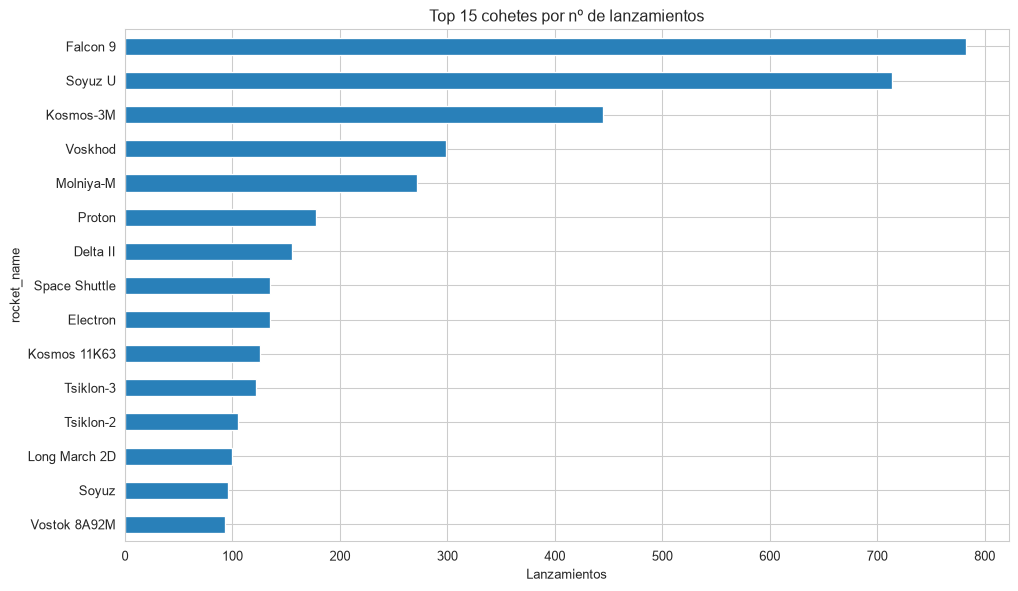

               lanzamientos  exitos     tasa_%
rocket_name                                   
Falcon 9                783     668  85.312899
Soyuz U                 714     694  97.198880
Kosmos-3M               445     423  95.056180
Voskhod                 299     286  95.652174
Molniya-M               272     259  95.220588
Proton                  178     153  85.955056
Delta II                155     153  98.709677
Space Shuttle           135     133  98.518519
Electron                135      87  64.444444
Kosmos 11K63            126     118  93.650794
Tsiklon-3               122     115  94.262295
Tsiklon-2               105     103  98.095238
Long March 2D           100      99  99.000000
Soyuz                    96      93  96.875000
Vostok 8A92M             93      92  98.924731


In [12]:
top_cohetes = launch[launch["rocket_name"].notna()].groupby("rocket_name").agg(
    lanzamientos=("id", "count"),
    exitos=("status_name", lambda s: (s == "Success").sum()),
).sort_values("lanzamientos", ascending=False).head(15)
top_cohetes["tasa_%"] = top_cohetes["exitos"] / top_cohetes["lanzamientos"] * 100
top_cohetes["lanzamientos"].plot(kind="barh", color="#2980b9", figsize=(12, 7))
plt.gca().invert_yaxis()
plt.title("Top 15 cohetes por nº de lanzamientos")
plt.xlabel("Lanzamientos")
plt.show()
print(top_cohetes)


In [13]:
# Fiabilidad por cohete (con mínimo de 20 vuelos)
fiables = top_cohetes[top_cohetes["lanzamientos"] >= 20].sort_values(
    "tasa_%", ascending=False)
fiables.head(15)[["lanzamientos", "tasa_%"]]


,lanzamientos,tasa_%
rocket_name,,
Long March 2D,100,99.000000
Vostok 8A92M,93,98.924731
Delta II,155,98.709677
Space Shuttle,135,98.518519
Tsiklon-2,105,98.095238
Soyuz U,714,97.198880
Soyuz,96,96.875000
Voskhod,299,95.652174
Molniya-M,272,95.220588


**Conclusión 5:** los cohetes derivados del **R-7** (Soyuz) son los más
lanzados de la historia; pero la familia **Falcon** de SpaceX ha alcanzado
en apenas una década un volumen histórico gracias a la reutilización de la
primera etapa. Entre los cohetes con más de 20 vuelos, los Falcon 9 y los
lanzadores chinos modernos presentan las mejores tasas de fiabilidad.


## 6. Hacia qué órbitas se lanza



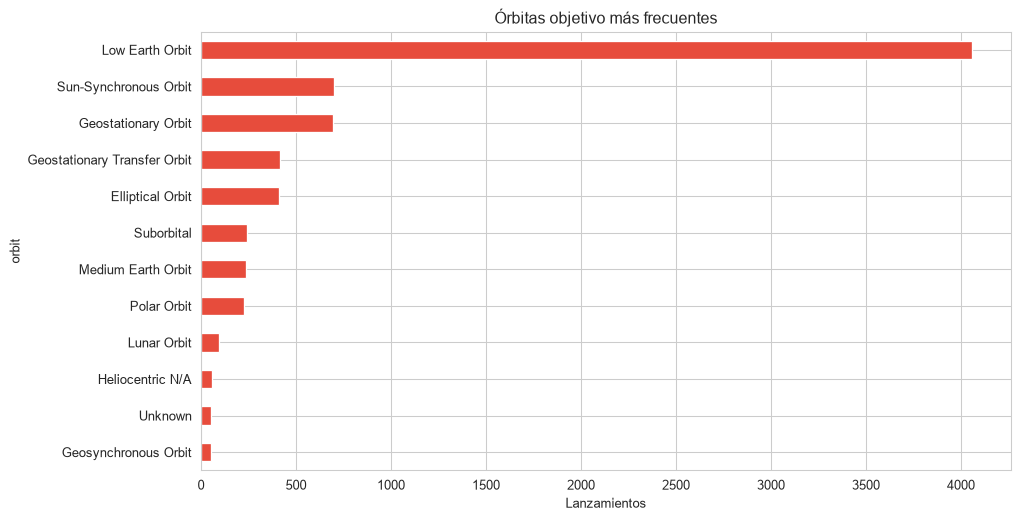

In [14]:
orbits = launch["orbit"].value_counts().head(12)
orbits.plot(kind="barh", color="#e74c3c", figsize=(11, 6))
plt.gca().invert_yaxis()
plt.title("Órbitas objetivo más frecuentes")
plt.xlabel("Lanzamientos")
plt.show()


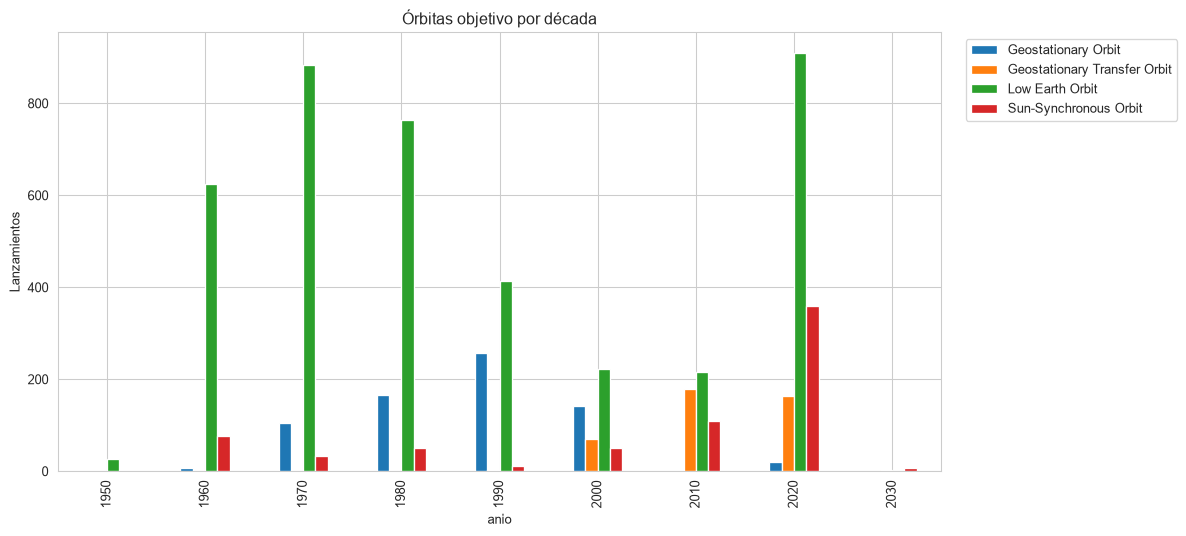

In [15]:
# Órbitas por década (top 4)
orb_dec = launch[launch["orbit"].isin(orbits.index[:4])]
tabla = orb_dec.pivot_table(index=launch["anio"] // 10 * 10,
                            columns="orbit", values="id", aggfunc="count").fillna(0)
tabla.plot(kind="bar", figsize=(12, 6))
plt.title("Órbitas objetivo por década")
plt.ylabel("Lanzamientos")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


**Conclusión 6:** la **órbita terrestre baja (LEO)** domina el sector con
diferencia: es donde están la ISS, las constelaciones de satélites
(Starlink, OneWeb) y los satélites de observación. Las órbitas de transferencia
geoestacionaria (GTO) siguen siendo clave para telecomunicaciones.


## 7. Desde dónde se lanza



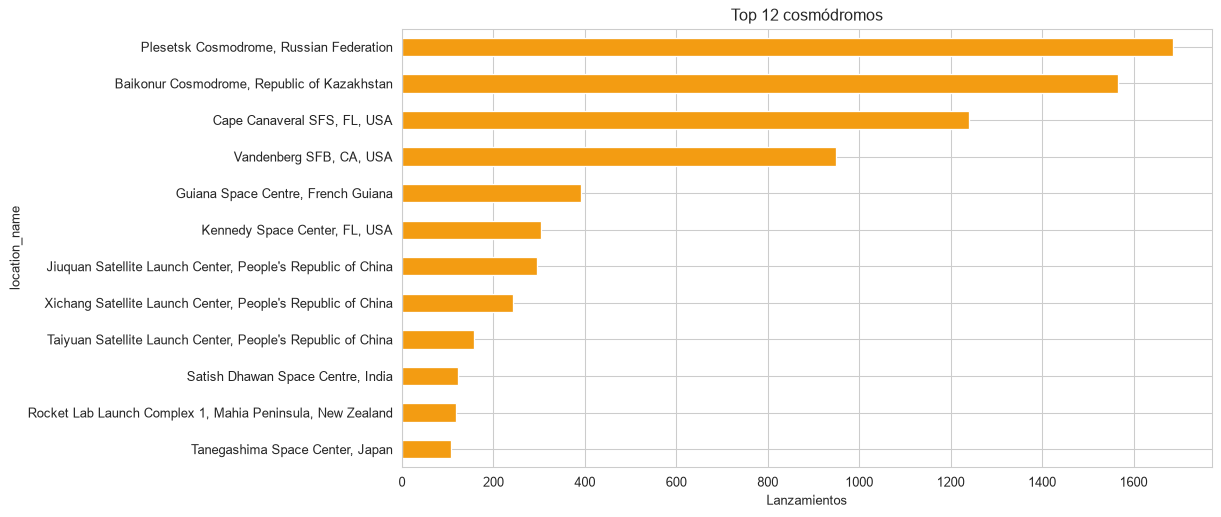

In [16]:
top_sitios = launch["location_name"].value_counts().head(12)
top_sitios.plot(kind="barh", color="#f39c12", figsize=(11, 6))
plt.gca().invert_yaxis()
plt.title("Top 12 cosmódromos")
plt.xlabel("Lanzamientos")
plt.show()


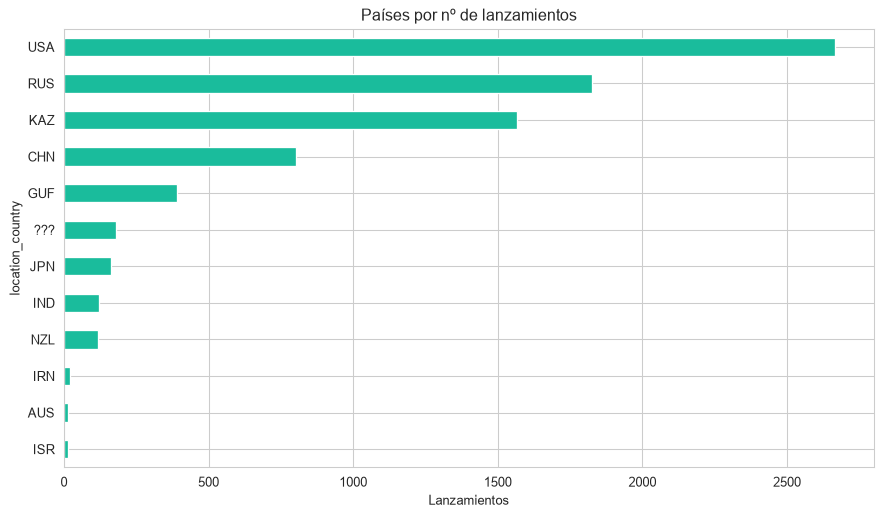

In [17]:
paises = launch["location_country"].value_counts().head(12)
paises.plot(kind="barh", color="#1abc9c", figsize=(11, 6))
plt.gca().invert_yaxis()
plt.title("Países por nº de lanzamientos")
plt.xlabel("Lanzamientos")
plt.show()


**Conclusión 7:** Estados Unidos, Rusia/Kazajistán (Baikonur) y China
concentran la inmensa mayoría de lanzamientos. Cabo Cañaveral y Baikonur
son los complejos de lanzamiento más activos de la historia, y SpaceX está
convirtiendo su base de Boca Chica (Texas) en un nuevo polo.


## 8. Tipos de misión y programas



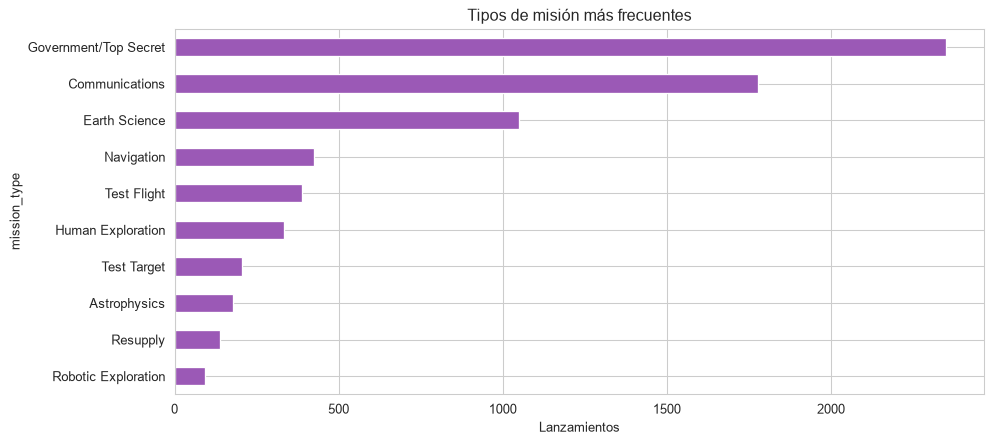

In [18]:
tipos = launch["mission_type"].value_counts().head(10)
tipos.plot(kind="barh", color="#9b59b6", figsize=(11, 5))
plt.gca().invert_yaxis()
plt.title("Tipos de misión más frecuentes")
plt.xlabel("Lanzamientos")
plt.show()


In [19]:
# Programas más repetidos (ej: Starlink, ISS...)
programas = launch["programs"].dropna().str.split(", ")
from collections import Counter
contador = Counter(p for lista in programas for p in lista)
pd.Series(contador).sort_values(ascending=False).head(10)


Starlink                        413
International Space Station     312
Soyuz                           200
Space Shuttle                   135
Mir                             108
Global Positioning System        81
GLONASS                          64
Commercial Resupply Services     61
Salyut                           54
Luna                             44
dtype: int64

**Conclusión 8:** los vuelos de prueba y las misiones de comunicación
fueron el grueso inicial; hoy la mayor parte son misiones comerciales de
despliegue de satélites, destacando el programa **Starlink**, que por sí
solo explica cientos de lanzamientos recientes.


## 9. Personas en el espacio: los astronautas



858 astronautas registrados


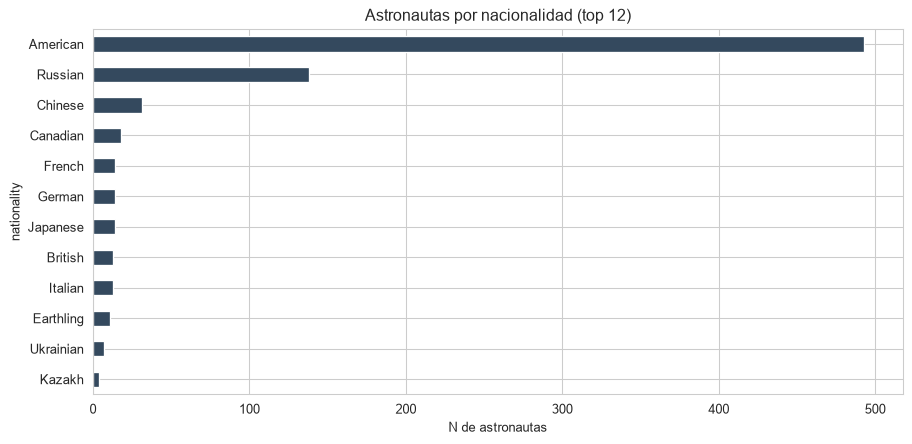

In [20]:
ast = query("SELECT * FROM astronauts")
print(f"{len(ast)} astronautas registrados")

if not ast.empty:
    nat = ast["nationality"].value_counts().head(12)
    if not nat.empty:
        nat.plot(kind="barh", color="#34495e", figsize=(11, 5))
        plt.gca().invert_yaxis()
        plt.title("Astronautas por nacionalidad (top 12)")
        plt.xlabel("N de astronautas")
        plt.show()
else:
    print("Aun no hay astronautas registrados en la base de datos.")


In [21]:
print(ast["status"].value_counts())
ast["flights_count"].describe()


status
Retired                         384
Active                          163
Deceased                        126
Occasional Spaceflight          124
In-Training                      23
Lost In Flight                   20
Lost In Training                  8
Died While In Active Service      7
Dismissed                         2
Resigned during Training          1
Name: count, dtype: int64


count       0
unique      0
top       NaN
freq      NaN
Name: flights_count, dtype: object

**Conclusión 9:** los programas estadounidense y soviético-ruso han
formado a la mayoría de los astronautas históricos, pero la lista de
nacionalidades se ha diversificado enormemente: hay astronautas de más de
40 países. La mayoría sigue siendo de agencias gubernamentales, aunque el
turismo espacial y las misiones privadas están creciendo.


## 10. Próximos lanzamientos

¿Qué nos espera en los próximos meses?


In [22]:
ahora = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
proximos = launch[launch["net"] > ahora].sort_values("net")
print(f"{len(proximos)} lanzamientos previstos a partir de hoy")
proximos[["name", "net", "rocket_name", "agency_name", "status_name"]].head(15)


365 lanzamientos previstos a partir de hoy


,name,net,rocket_name,agency_name,status_name
7578,Long March 8A | Unknown Payload,2026-08-04T08:50:00Z,Long March 8A,China Aerospace Science and Technology Corpora...,Go
7579,Falcon 9 Block 5 | Starlink Group 17-53,2026-08-04T14:00:00Z,Falcon 9,SpaceX,Go
7580,Smart Dragon 3 | Unknown Payload,2026-08-05T02:35:00Z,Smart Dragon 3,China Rocket Co. Ltd.,Go
7581,Falcon 9 Block 5 | BlueBird 11-13 (Block 2 #6-8),2026-08-05T07:42:00Z,Falcon 9,SpaceX,Go
7582,Falcon 9 Block 5 | Starlink Group 17-38,2026-08-08T14:00:00Z,Falcon 9,SpaceX,Go
7583,Long March 7A | Unknown Payload,2026-08-09T11:00:00Z,Long March 7A,China Aerospace Science and Technology Corpora...,TBD
7584,Falcon 9 Block 5 | Starlink Group 10-19,2026-08-10T14:49:00Z,Falcon 9,SpaceX,Go
7585,Falcon 9 Block 5 | Starlink Group 17-49,2026-08-12T02:00:00Z,Falcon 9,SpaceX,Go
7586,Falcon 9 Block 5 | Globalstar 2-R Mission 1 (x 9),2026-08-16T01:12:00Z,Falcon 9,SpaceX,TBD
7587,Long March 12 | Unknown Payload,2026-08-17T02:00:00Z,Long March 12,China Aerospace Science and Technology Corpora...,TBD


**Conclusión 10:** el calendario de próximos lanzamientos confirma el
ritmo industrial actual: decenas de misiones al mes, dominadas por la
constelación Starlink de SpaceX y las misiones de abastecimiento y
rotación de tripulación a la ISS, con los grandes proyectos lunares
(Artemis) y las nuevas misiones interplanetarias como hitos destacados.


## 11. Resumen de conclusiones

1. **Crecimiento imparable**: de 3 lanzamientos en 1957 a más de 250 al año
   hoy; la última década concentra más actividad que las cinco anteriores.
2. **Fiabilidad**: la tasa de éxito global supera el 90 % y sigue mejorando.
3. **Dominio privado**: SpaceX ha transformado el sector; los cohetes
   reutilizables (Falcon) alcanzan volúmenes y fiabilidad récord.
4. **LEO manda**: la órbita baja es el gran negocio (constelaciones, ISS).
5. **Geografía concentrada**: EEUU, Rusia/Kazajistán y China concentran
   la actividad; cabos y cosmódromos históricos siguen activos.
6. **Más gente que nunca**: cientos de astronautas de decenas de países,
   y el acceso al espacio se está democratizando.

> Estos datos alimentan la app **Órbita** (streamlit) y el **chat RAG**
> que permite preguntar por ellos en lenguaje natural.


In [ ]:
ahora = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
proximos = launch[launch["net"] > ahora].sort_values("net")
print(f"{len(proximos)} lanzamientos previstos a partir de hoy")
proximos[["name", "net", "rocket_name", "agency_name", "status_name"]].head(15)
ahora = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
proximos = launch[launch["net"] > ahora].sort_values("net")
print(f"{len(proximos)} lanzamientos previstos a partir de hoy")
proximos[["name", "net", "rocket_name", "agency_name", "status_name"]].head(15)


In [ ]:
ahora = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
proximos = launch[launch["net"] > ahora].sort_values("net")
print(f"{len(proximos)} lanzamientos previstos a partir de hoy")
proximos[["name", "net", "rocket_name", "agency_name", "status_name"]].head(15)
